# 01 — Inventário e qualidade da base EEG-RAB2
Objetivo: montar os metadados a partir dos nomes dos arquivos, checar integridade de cada registro
(duração, NaNs, canais planos/saturados) e gerar o cache parquet usado pelos demais notebooks.

**Fatos da tese (cap. 5):** 39 participantes (21 CTR, 18 TCM), EEG a 300 Hz, sistema 10-20, trecho RAB2 = 2º relato
autobiográfico após o estímulo musical. **P40 (TCM) veio vazio** → 38 participantes utilizáveis (21 CTR, 17 TCM). Rótulos afetivos individuais, idade e MEEM **não** estão nos arquivos.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_io import build_metadata, load_subject, METADATA_PATH, FS, CHANNELS, ROOT

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

## Metadados a partir dos nomes

In [2]:
meta = build_metadata()
meta.to_csv(METADATA_PATH, index=False)
print(meta.shape)
display(pd.crosstab(meta["group"], meta["sex"], margins=True))
print("Arquivos sem sinal (excluídos):", meta.loc[~meta.usable, ["subject", "file", "file_bytes"]].to_dict("records"))
meta = meta[meta.usable].reset_index(drop=True)
display(pd.crosstab(meta["group"], meta["sex"], margins=True))

(39, 13)


sex,F,M,All
group,,,
CTR,14,7,21
TCM,15,3,18
All,29,10,39


Arquivos sem sinal (excluídos): [{'subject': 'P40', 'file': 'P40_TCM_F_EEG_RAB2.csv', 'file_bytes': 1}]


sex,F,M,All
group,,,
CTR,14,7,21
TCM,14,3,17
All,28,10,38


## Integridade por participante
Primeira leitura dos CSVs (~1,3 GB) — lenta; converte para parquet float32 em `data/processed/signals/`.

In [3]:
rows, ch_rows = [], []
for r in meta.itertuples(index=False):
    x = load_subject(r.subject, meta)
    std = x.std(axis=0)
    rows.append({
        "subject": r.subject, "group": r.group, "sex": r.sex,
        "n_samples": x.shape[0], "duration_s": x.shape[0] / FS,
        "n_nan": int(np.isnan(x).sum()),
        "n_flat_channels": int((std < 0.5).sum()),
        "frac_abs_gt_500uV": float((np.abs(x) > 500).mean()),
        "median_std_uV": float(np.median(std)),
    })
    for ch, s, mn, mx in zip(CHANNELS, std, x.min(axis=0), x.max(axis=0)):
        ch_rows.append({"subject": r.subject, "group": r.group, "channel": ch, "std": s, "min": mn, "max": mx})

inv = pd.DataFrame(rows)
chq = pd.DataFrame(ch_rows)
inv.to_csv(ROOT / "reports" / "inventario.csv", index=False)
inv.describe().T

,count,mean,std,min,25%,50%,75%,max
n_samples,38.0,87940.684211,70302.097236,11623.000000,48109.500000,63943.000000,99205.000000,291042.000000
duration_s,38.0,293.135614,234.340324,38.743333,160.365000,213.143333,330.683333,970.140000
n_nan,38.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
n_flat_channels,38.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
frac_abs_gt_500uV,38.0,0.002537,0.003283,0.000000,0.000235,0.001236,0.003620,0.015425
median_std_uV,38.0,37.390386,19.663994,6.095411,23.427496,32.755821,50.724734,79.418831


In [4]:
display(inv.groupby("group")[["duration_s", "median_std_uV", "frac_abs_gt_500uV"]].describe().T)
print("Participantes com canais planos:", inv.loc[inv.n_flat_channels > 0, "subject"].tolist())
print("Participantes com NaN:", inv.loc[inv.n_nan > 0, "subject"].tolist())

group                           CTR         TCM
duration_s        count   21.000000   17.000000
                  mean   383.540635  181.458824
                  std    273.836111   96.336520
                  min     42.240000   38.743333
                  25%    177.726667  128.786667
                  50%    287.383333  168.563333
                  75%    540.400000  213.096667
                  max    970.140000  426.803333
median_std_uV     count   21.000000   17.000000
                  mean    34.105054   41.448739
                  std     16.494048   22.857110
                  min      9.716617    6.095411
                  25%     23.019466   24.651587
                  50%     31.906635   35.166328
                  75%     41.285076   65.883797
                  max     78.272339   79.418831
frac_abs_gt_500uV count   21.000000   17.000000
                  mean     0.002092    0.003087
                  std      0.002273    0.004229
                  min      0.000000    0.000000
                  25%      0.000269    0.000050
                  50%      0.001026    0.001870
                  75%      0.003694    0.003398
                  max      0.007728    0.015425

Participantes com canais planos: []
Participantes com NaN: []


## Duração do trecho RAB2 por grupo

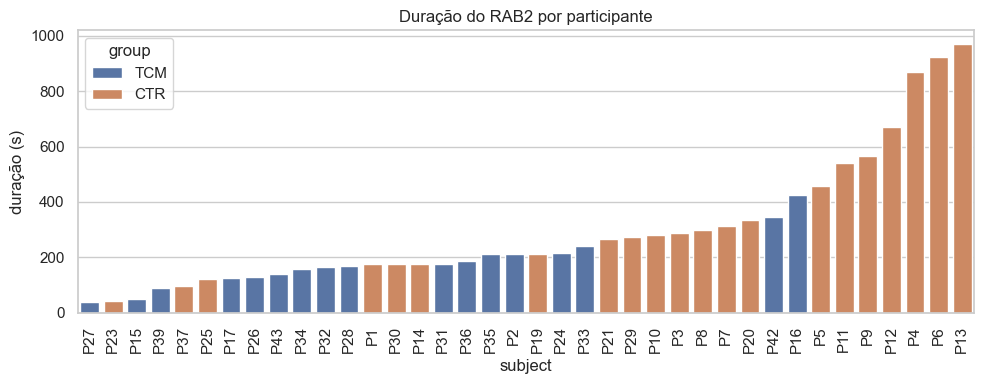

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
order = inv.sort_values("duration_s")
sns.barplot(data=order, x="subject", y="duration_s", hue="group", dodge=False, ax=ax)
ax.set_ylabel("duração (s)"); ax.tick_params(axis="x", rotation=90)
ax.set_title("Duração do RAB2 por participante")
fig.tight_layout(); fig.savefig(FIG / "01_duracao.png", dpi=120)

## Amplitude (desvio-padrão) por canal × participante
Canais com std muito alto em muitos sujeitos sugerem artefato sistemático (ex.: frontais com piscadas);
linhas destoantes indicam registros ruidosos.

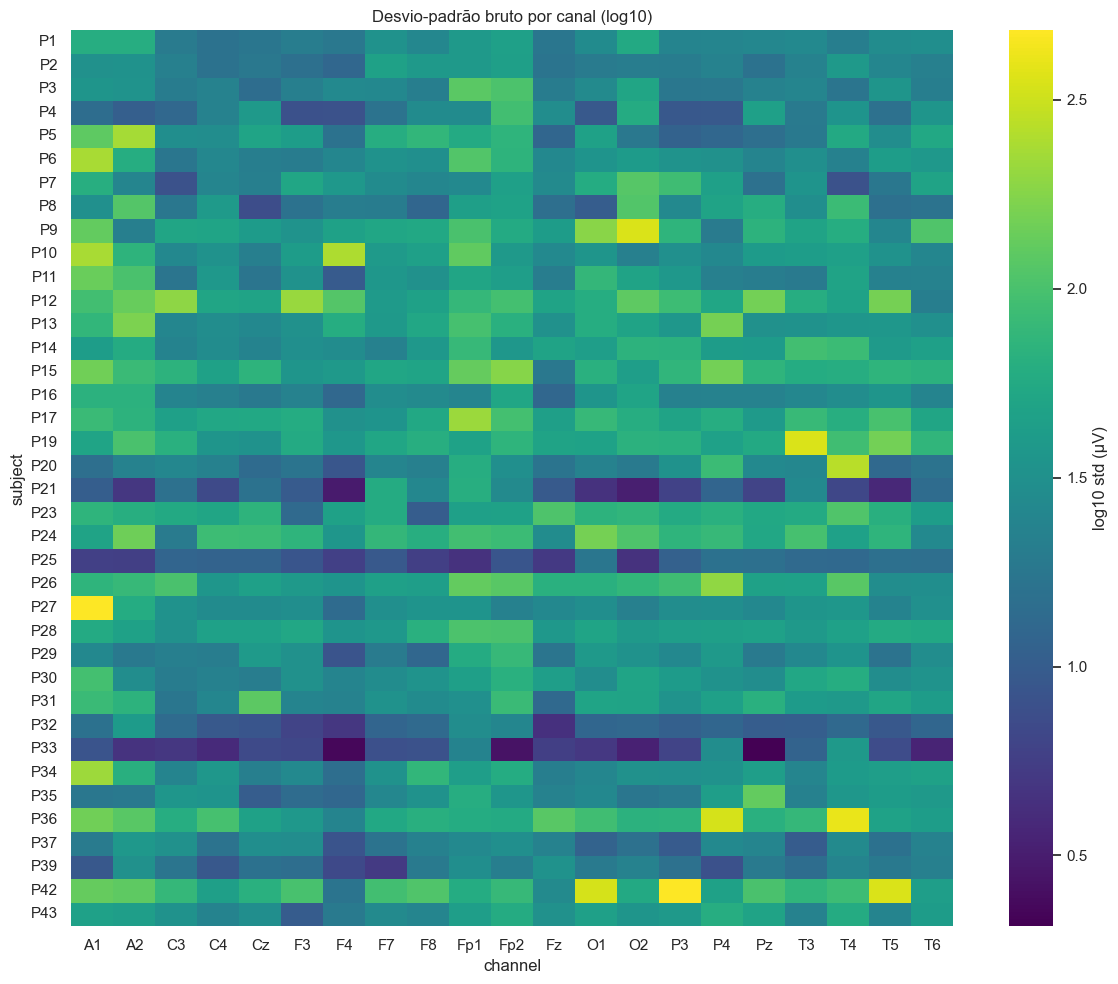

In [6]:
pivot = chq.pivot(index="subject", columns="channel", values="std")
pivot = pivot.loc[meta["subject"]]
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(np.log10(pivot + 1e-3), cmap="viridis", ax=ax, cbar_kws={"label": "log10 std (µV)"})
ax.set_title("Desvio-padrão bruto por canal (log10)")
fig.tight_layout(); fig.savefig(FIG / "01_std_heatmap.png", dpi=120)

## Checklist
- [ ] Conferir se durações muito curtas comprometem o número de janelas (5 s).
- [ ] Levar à orientadora: ordem dos 21 canais, rótulos de polaridade do RAB2, idade e MEEM
  (preencher colunas `age`, `meem`, `polarity_rab2`, `affect_rab2` em `data/metadata.csv`).